# Sequence-to-function models part 2: base-resolution chromatin accessibility with ChromBPNet

**Case study: sequence determinants of chromatin accessibility in mouse microglia**

Zemke NR, Armand EJ, Wang W, et al. *Conserved and divergent gene regulatory programs of the mammalian neocortex.* Nature (2023) 624:390–402. https://doi.org/10.1038/s41586-023-06819-6

Pampari A, Shcherbina A, Kvon EZ, et al. *ChromBPNet: bias factorized, base-resolution deep learning models of chromatin accessibility reveal cis-regulatory sequence syntax, transcription factor footprints and regulatory variants.* bioRxiv (2024). https://github.com/kundajelab/chrombpnet

**Background**

Each ATAC-seq read marks a position where Tn5 inserted. A bound transcription factor (TF) protects the DNA beneath it from insertion (a footprint) and increases accessibility of the flanking sequence. CREsted (part 1) predicts one accessibility value per region and cell type. ChromBPNet predicts, for a single cell type, the distribution of insertions over the central 1,000 bp of a 2,114 bp input (**profile**) and their total number (**counts**). At this resolution, the sequence preference of Tn5 contributes substantially to the signal. ChromBPNet therefore first trains a **bias model** on background regions, then trains the main model with the bias model frozen. The main model alone is used for interpretation.

We train ChromBPNet on the microglia of the mouse motor cortex dataset used in part 1. Microglia development requires PU.1 (*Spi1*) and IRF8; MEF2C, MAFB and CEBP factors are part of the microglia regulatory program. FIRE, an intronic enhancer of *Csf1r*, is required for microglia: mice lacking FIRE have none.

**Research questions:**

1. How well can base-resolution Tn5 insertions be predicted from sequence?
2. How much of the profile reflects the sequence preference of Tn5?
3. Which TF motifs does the model use?
4. Which bases of FIRE determine its predicted accessibility?

Training takes several hours on a GPU; the training commands are shown but not executed, and the trained models are loaded instead. All other steps run on a CPU.

**Note**:

ChromBPNet 1.0.1 requires TensorFlow 2.8 (Python 3.10, CUDA 11.2). `numpy<1.24` and `pyBigWig` are needed but not installed by ChromBPNet.

    mamba create -n chrombpnet -c conda-forge -c bioconda python=3.10 pip cudatoolkit=11.2 cudnn=8.1 htslib ucsc-bedgraphtobigwig ucsc-bigwigtobedgraph meme ipykernel
    mamba activate chrombpnet
    pip install chrombpnet==1.0.1 "numpy<1.24" pyBigWig

Register the environment as a Jupyter kernel (in a terminal, not in this notebook):

```
mamba activate chrombpnet
python -m ipykernel install --user --name chrombpnet --display-name "Python (chrombpnet)" \
    --env PATH "${CONDA_PREFIX}/bin:${PATH}" --env PYTHONPATH ""
jupyter kernelspec list   # the kernel chrombpnet should be listed
```

`--env PATH` adds the `bin` folder of the environment to the `PATH` of the kernel, so that the command-line tools of the environment (`chrombpnet`, and `tomtom` used by TF-MoDISco) are found, even when Jupyter itself is started from another environment. `--env PYTHONPATH ""` keeps the Python packages of that other environment (for example a Jupyter installation loaded as a module) out of the kernel.

Then (re)start Jupyter and select the kernel "Python (chrombpnet)" (Kernel > Change Kernel). Training additionally requires `bedtools`, `samtools` and a GPU supported by TensorFlow 2.8 (up to the A100; on newer GPUs it falls back to the CPU).

## Step 0: set up working directory

Data are stored in `data/chrombpnet` and results in `results/chrombpnet`, next to this notebook.

In [1]:
%matplotlib inline
import json
import gzip
import shutil
import tarfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import deepdish as dd
import logomaker
from IPython.display import Image

plt.rcParams["figure.dpi"] = 80

DATA = Path("data/chrombpnet")
GENOME = DATA / "genome"
RESULTS = Path("results/chrombpnet")
for folder in (DATA, GENOME, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

Download chromosomes 9 and 18 of mm10 (the test chromosomes, Step 3) and the chromosome sizes from UCSC.

In [2]:
UCSC = "https://hgdownload.soe.ucsc.edu/goldenPath/mm10"
FASTA = GENOME / "mm10_chr9_chr18.fa"
if not FASTA.exists():
    with open(FASTA, "wb") as out:
        for chrom in ["chr9", "chr18"]:
            urlretrieve(f"{UCSC}/chromosomes/{chrom}.fa.gz", GENOME / f"{chrom}.fa.gz")
            with gzip.open(GENOME / f"{chrom}.fa.gz") as f:
                shutil.copyfileobj(f, out)
            (GENOME / f"{chrom}.fa.gz").unlink()
CHROM_SIZES = GENOME / "mm10.chrom.sizes"
if not CHROM_SIZES.exists():
    urlretrieve(f"{UCSC}/bigZips/mm10.chrom.sizes", CHROM_SIZES)

Download the trained models and derived data (about 340 MB), made with the scripts in `scripts/chrombpnet/`. If the course provides `chrombpnet_microglia.tar.gz`, place it in `data/chrombpnet/` and the next cell will use it.

In [3]:
bundle = DATA / "chrombpnet_microglia.tar.gz"
if not (DATA / "models").exists():
    if not bundle.exists():
        print("Downloading the data of this practical (about 340 MB)...")
        urlretrieve("https://students.aertslab.org/regulatory_genomics_2026/chrombpnet_microglia.tar.gz", bundle)
    with tarfile.open(bundle) as tar:
        tar.extractall(DATA)

In [4]:
!ls {DATA} {DATA}/*/

data/chrombpnet:
chrombpnet_microglia.tar.gz  fragments_chr18.tsv.gz.tbi  nonpeaks_negatives.bed
evaluation		     genome			 peaks.narrowPeak
fold_0.json		     insertions_chr9_chr18.bw	 training
footprints		     models
fragments_chr18.tsv.gz	     modisco

data/chrombpnet/evaluation/:
bias_metrics.json    bw_shift_qc.png	      chrombpnet_predictions.h5
bias_predictions.h5  chrombpnet_metrics.json

data/chrombpnet/footprints/:
chrombpnet_footprints.h5  chrombpnet_nobias_footprints.h5  motifs.tsv

data/chrombpnet/genome/:
mm10_chr9_chr18.fa  mm10_chr9_chr18.fa.fai  mm10.chrom.sizes

data/chrombpnet/models/:
bias.h5  bias_model_scaled.h5  chrombpnet.h5  chrombpnet_nobias.h5

data/chrombpnet/modisco/:
bias_profile.h5		 chrombpnet_counts_tomtom.tsv
bias_profile_tomtom.tsv  chrombpnet_profile.h5
chrombpnet_counts.h5	 chrombpnet_profile_tomtom.tsv

data/chrombpnet/training/:
bias.log  bias_model_params.tsv  chrombpnet.log  chrombpnet_model_params.tsv


## Step 1: from reads to fragments

GEO provides only count matrices for this dataset, so the fragments were generated from the reads in the Sequence Read Archive (22 runs, 6.9 billion read pairs; `scripts/chrombpnet/00_download_refs.sh` to `scripts/chrombpnet/03_pseudobulk.sh`, about 5 hours on a cluster). In 10x multiome ATAC data, a third read carries the 16 bp cell barcode. `chromap` aligns the two genomic reads to mm10, corrects barcodes against the 10x barcode list, removes PCR duplicates per cell and reports one line per fragment. Fragments of barcodes annotated as microglia (subclass `MGC`) were kept. The command for one run (environment `envs/chrombpnet-prep.yml`):

```bash
# read 1 and read 3: the two ends of the fragment; read 2: 8 bp spacer + the 16 bp cell barcode
prefetch SRR24107544
fastq-dump --split-files SRR24107544
chromap --preset atac -x mm10.chromap.index -r mm10.fa \
    -1 SRR24107544_1.fastq -2 SRR24107544_3.fastq -b SRR24107544_2.fastq --read-format r1:0:-1,r2:0:-1,bc:8:23 \
    --barcode-whitelist atac_rc_737K-arc-v1.txt --barcode-translate translate_atac_rc_to_gex.tsv \
    -o SRR24107544.fragments.tsv
```

The fragment file of chromosome 18: position, cell barcode and number of supporting read pairs.

In [5]:
fragments = pd.read_csv(f"{DATA}/fragments_chr18.tsv.gz", sep="\t", header=None,
                        names=["chrom", "start", "end", "barcode", "reads"])
fragments.head()

,chrom,start,end,barcode,reads
0,chr18,3000501,3000632,mop3c2_GGTGCTTCAGGACACA,5
1,chr18,3000556,3000632,mop3c2_GGTGCTTCAGGACACA,1
2,chr18,3000616,3000809,mop3c2_AAGCTTGGTTGAAGCC,1
3,chr18,3001236,3001310,mop2c2_TGATCGAGTGCTGTAA,2
4,chr18,3001847,3002182,mop2c1_TGGGCCTAGTTAGCCG,1


In [6]:
print(len(fragments), "fragments on chr18 from", fragments["barcode"].nunique(), "nuclei")

1268974 fragments on chr18 from 3115 nuclei


Genome-wide, 43.4 million fragments from 3,115 nuclei are pooled into one pseudobulk. The fragment lengths show the nucleosome pattern: sub-nucleosomal (< 150 bp), mono-nucleosomal (~200 bp) and di-nucleosomal (~400 bp) fragments.

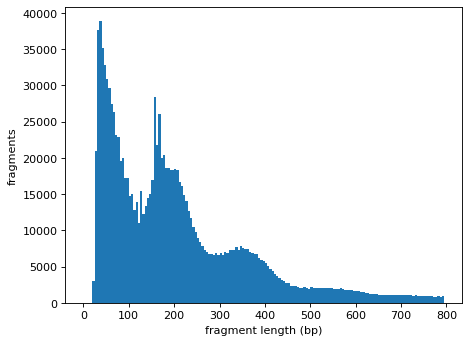

In [7]:
plt.hist(fragments["end"] - fragments["start"], bins=np.arange(0, 800, 5))
plt.xlabel("fragment length (bp)")
plt.ylabel("fragments")
plt.show()

## Step 2: Tn5 insertions

Each fragment end is a Tn5 insertion. ChromBPNet is trained on insertion counts per base, stored as a bigWig file (here for chromosomes 9 and 18). Below are the insertions around the summit of the FIRE peak (chr18:61,108,642), over the 2,114 bp model input; the dashed lines delimit the central 1,000 bp that is predicted.

In [8]:
import pyBigWig

peaks = pd.read_csv(f"{DATA}/peaks.narrowPeak", sep="\t", header=None,
                    names=["chrom", "start", "end", "name", "score", "strand", "signal", "p", "q", "summit"])
fire = peaks[peaks["name"] == "microglia_peak_57271c"].iloc[0]
FIRE_SUMMIT = fire["start"] + fire["summit"]
print("FIRE summit:", fire["chrom"], FIRE_SUMMIT)

insertions = pyBigWig.open(f"{DATA}/insertions_chr9_chr18.bw")
fire_obs = np.nan_to_num(insertions.values("chr18", FIRE_SUMMIT - 1057, FIRE_SUMMIT + 1057, numpy=True))
print("insertions in the central 1,000 bp:", fire_obs[557:1557].sum())

FIRE summit: chr18 61108642
insertions in the central 1,000 bp: 5107.0


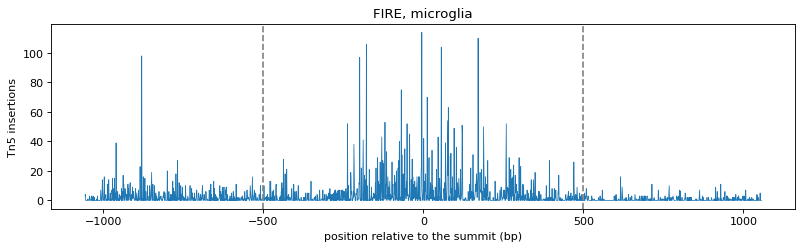

In [9]:
plt.figure(figsize=(12, 3))
plt.plot(np.arange(-1057, 1057), fire_obs, lw=0.7)
plt.axvline(-500, color="grey", ls="--")
plt.axvline(500, color="grey", ls="--")
plt.xlabel("position relative to the summit (bp)")
plt.ylabel("Tn5 insertions")
plt.title("FIRE, microglia")
plt.show()

Counts vary strongly between neighbouring bases, owing to sampling noise and to the sequence preference of Tn5.

## Step 3: peaks, background regions and test chromosomes

Training regions are 2,114 bp windows centred on:

- **peak summits**: MACS3 peaks called on the insertions (q ≤ 0.01), excluding regions near blacklisted sequence;
- **background regions**: regions outside peaks with GC content matched to the peaks. They provide examples of low accessibility and are used to train the bias model.

Commands from `scripts/chrombpnet/03_pseudobulk.sh` and `scripts/chrombpnet/04_prep_chrombpnet.sh`:

```bash
# peaks on the Tn5 insertions (ins.bed: both ends of each fragment), as in the ChromBPNet tutorial
macs3 callpeak -t ins.bed -f BED -g mm -n microglia -p 0.01 --shift -75 --extsize 150 --nomodel --keep-dup all --call-summits
# test and validation chromosomes, as in part 1
chrombpnet prep splits -c mm10.main.chrom.sizes -tcr chr9 chr18 -vcr chr8 chr10 -op fold_0
# background regions with the GC content of the peaks
chrombpnet prep nonpeaks -g mm10.fa -p peaks.narrowPeak -c mm10.main.chrom.sizes -fl fold_0.json -br mm10-blacklist.v2.bed -o nonpeaks
```

In [10]:
peaks.head()

,chrom,start,end,name,score,strand,signal,p,q,summit
0,chr1,3121386,3121604,microglia_peak_1,72,.,3.55690,7.22850,5.28781,99
1,chr1,3292550,3292978,microglia_peak_2,369,.,7.58017,36.99340,34.67910,230
2,chr1,3293000,3293403,microglia_peak_3,181,.,5.00582,18.14520,16.00280,203
3,chr1,3293471,3293844,microglia_peak_4,332,.,7.11370,33.29650,31.00920,249
4,chr1,3293924,3294075,microglia_peak_5,80,.,3.26531,8.02145,6.05885,84


In [11]:
nonpeaks = pd.read_csv(f"{DATA}/nonpeaks_negatives.bed", sep="\t", header=None,
                       names=["chrom", "start", "end", "name", "score", "strand", "signal", "p", "q", "summit"])
print(len(peaks), "peaks,", len(nonpeaks), "background regions")

154781 peaks, 296659 background regions


The files have one line per summit; `summit` is the offset of the summit from `start`. GC content of 2,000 random peaks and background regions on chromosomes 9 and 18:

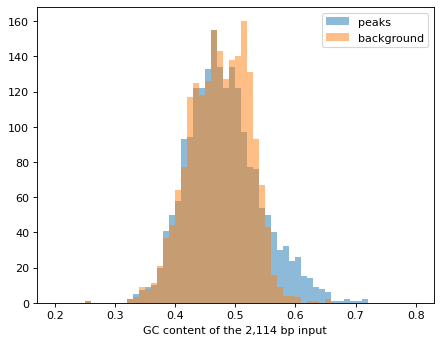

In [12]:
import pyfaidx

genome = pyfaidx.Fasta(str(FASTA))

def gc_content(regions):
    gc = []
    for _, r in regions.iterrows():
        centre = r["start"] + r["summit"]
        seq = str(genome[r["chrom"]][centre - 1057:centre + 1057]).upper()
        gc.append((seq.count("G") + seq.count("C")) / len(seq))
    return gc

test_chroms = ["chr9", "chr18"]
bins = np.linspace(0.2, 0.8, 61)
plt.hist(gc_content(peaks[peaks["chrom"].isin(test_chroms)].sample(2000, random_state=0)), bins=bins, alpha=0.5, label="peaks")
plt.hist(gc_content(nonpeaks[nonpeaks["chrom"].isin(test_chroms)].sample(2000, random_state=0)), bins=bins, alpha=0.5, label="background")
plt.xlabel("GC content of the 2,114 bp input")
plt.legend()
plt.show()

The distributions overlap, except for a tail of GC-rich peaks (e.g. CpG island promoters).

**Why should the background regions be GC-matched to the peaks?**

As in part 1, chromosomes 8 and 10 are used for validation (early stopping) and chromosomes 9 and 18 for testing. FIRE, on chromosome 18, is a test region.

In [13]:
json.load(open(f"{DATA}/fold_0.json"))

{'test': ['chr9', 'chr18'],
 'valid': ['chr8', 'chr10'],
 'train': ['chr1',
  'chr2',
  'chr3',
  'chr4',
  'chr5',
  'chr6',
  'chr7',
  'chr11',
  'chr12',
  'chr13',
  'chr14',
  'chr15',
  'chr16',
  'chr17',
  'chr19',
  'chrX',
  'chrY']}

## Step 4: the Tn5 bias model

The bias model has the same two outputs as ChromBPNet, but a small architecture with a short receptive field, and it is trained only on background regions with low counts. This restricts it to learning the sequence preference of Tn5. `-b 0.5` keeps background regions with fewer than half the counts of the weakest 1% of peaks, the recommended value for ATAC-seq. `scripts/chrombpnet/05_bias.sh` took 4.5 hours on an A100 GPU, of which 15 minutes training; the remainder is the interpretation described in Steps 7 and 8.

The training commands of this step and Step 5 need the full microglia fragment file and the complete mm10 sequence, which are not part of the download of Step 0. To rerun the training (on a GPU, with `bedtools` and `samtools` installed), download them into `data/chrombpnet` and run the commands from there:

```bash
cd data/chrombpnet
wget https://students.aertslab.org/regulatory_genomics_2026/chrombpnet_microglia_training.tar   # about 500 MB
tar -xf chrombpnet_microglia_training.tar   # microglia.fragments.tsv.gz (+ index), mm10.main.chrom.sizes
wget https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.fa.gz
gunzip mm10.fa.gz
```

```bash
chrombpnet bias pipeline -ifrag microglia.fragments.tsv.gz -d ATAC -g mm10.fa -c mm10.main.chrom.sizes \
    -p peaks.narrowPeak -n nonpeaks_negatives.bed -fl fold_0.json -b 0.5 -o bias
```

Before training, the pipeline derives the motif at the insertion sites from the data. It should match the Tn5 motif, which is palindromic because Tn5 inserts as a dimer.

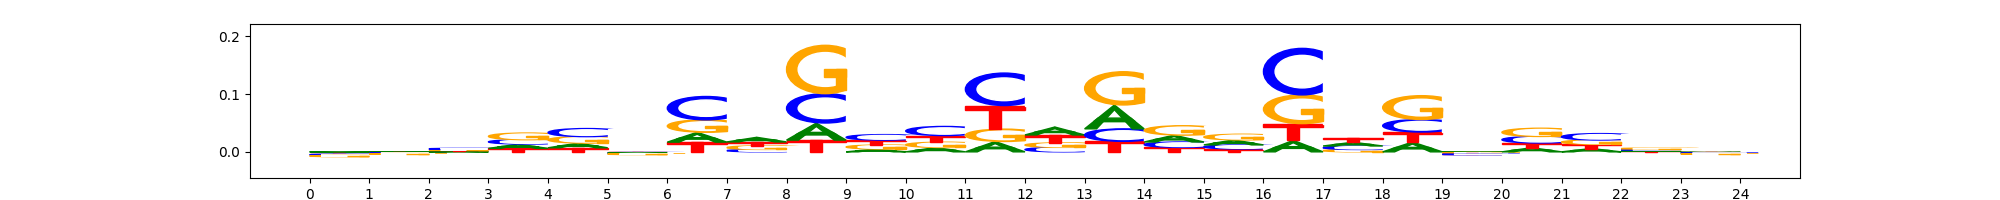

In [14]:
Image(f"{DATA}/evaluation/bw_shift_qc.png")

Model parameters (4 dilated convolution layers, 128 filters) and training curve. Training stops after 5 epochs without improvement on the validation set, and the epoch with the lowest validation loss is kept (dashed line).

In [15]:
pd.read_csv(f"{DATA}/training/bias_model_params.tsv", sep="\t", header=None, names=["parameter", "value"])

,parameter,value
0,counts_loss_weight,1.0
1,filters,128
2,n_dil_layers,4
3,inputlen,2114
4,outputlen,1000
5,max_jitter,0
6,chr_fold_path,/data/groups/vib.ai/stein.aerts/nkemp/software...
7,negative_sampling_ratio,1.0


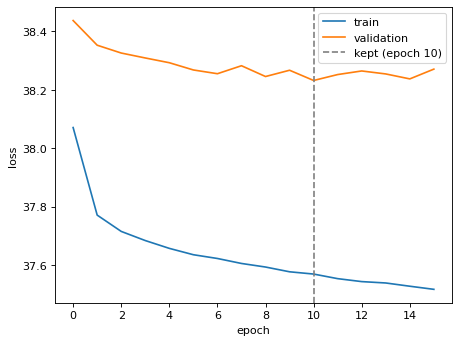

In [16]:
bias_log = pd.read_csv(f"{DATA}/training/bias.log")
best = bias_log.loc[bias_log["val_loss"].idxmin(), "epoch"]
plt.plot(bias_log["epoch"], bias_log["loss"], label="train")
plt.plot(bias_log["epoch"], bias_log["val_loss"], label="validation")
plt.axvline(best, color="grey", ls="--", label=f"kept (epoch {best})")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

Counts performance: a bias model should predict counts in background regions, where they depend on Tn5 preference, but not in peaks, where they depend on TF binding.

In [17]:
json.load(open(f"{DATA}/evaluation/bias_metrics.json"))["counts_metrics"]

{'peaks_and_nonpeaks': {'spearmanr': 0.1926253127297511,
  'pearsonr': 0.2292490987927005,
  'mse': 6.616584272812741},
 'nonpeaks': {'spearmanr': 0.6193601247866952,
  'pearsonr': 0.6230090475371513,
  'mse': 0.9143969469197185},
 'peaks': {'spearmanr': 0.17554991730804748,
  'pearsonr': 0.1773382810010117,
  'mse': 12.318771598705764}}

Motifs used by the bias model: TF-MoDISco motifs from the contribution scores (Steps 7 and 8) of 30,000 peaks, compared with a database of TF and Tn5 motifs by TOMTOM. `qval0` is the q-value of the best match. TOMTOM runs once per motif and takes several minutes for the three TF-MoDISco results of this notebook, so the tables were made in advance (`scripts/chrombpnet/08_modisco.sh`) with:

```python
from modiscolite.report import run_tomtom
from chrombpnet.data import DefaultDataFile, get_default_data_path

motif_db = get_default_data_path(DefaultDataFile.motifs_meme)   # TF motifs and Tn5 motifs, comes with ChromBPNet
run_tomtom("modisco/bias_profile.h5", None, motif_db, top_n_matches=3)
```

(`modiscolite.report` switches matplotlib to a non-interactive backend when it is imported, so plots no longer appear in the notebook after importing it.)

In [18]:
bias_motifs = pd.read_csv(f"{DATA}/modisco/bias_profile_tomtom.tsv", sep="\t")
bias_motifs

,pattern,num_seqlets,match0,qval0,match1,qval1,match2,qval2
0,pos_patterns.pattern_0,12967,TN5_2,3.975460e-08,TN5_1,0.000010,TN5_7,0.000926
1,pos_patterns.pattern_1,11227,TN5_2,7.021100e-05,TN5_1,0.000091,TN5_3,0.000798
2,pos_patterns.pattern_2,1746,TN5_1,1.949630e-03,ZFX_MOUSE.H11MO.0.B,0.010902,P53_MOUSE.H11MO.0.A,0.137043
3,pos_patterns.pattern_3,1721,TN5_3,1.851780e-09,TN5_1,0.000104,TN5_7,0.001256
4,pos_patterns.pattern_4,1090,TN5_3,1.901330e-04,TN5_7,0.001626,TN5_1,0.003932
5,pos_patterns.pattern_5,755,TN5_3,2.822750e-08,TN5_1,0.000002,TN5_4,0.004862
6,pos_patterns.pattern_6,561,TN5_3,1.207490e-06,TN5_4,0.000638,TN5_5,0.000638
7,pos_patterns.pattern_7,233,PRDM6_HUMAN.H11MO.0.C,1.301200e-01,ZNF384_MA1125.1,0.130120,STAT1_MOUSE.H11MO.0.A,0.232722
8,pos_patterns.pattern_8,206,TN5_3,1.776640e-05,TN5_1,0.009013,TN5_4,0.011770
9,pos_patterns.pattern_9,127,RREB1_MA0073.1,1.000000e+00,EGR2_HUMAN.H11MO.0.A,1.000000,EGR1_HUMAN.H11MO.0.A,1.000000


Contribution weight matrices (CWMs: mean contribution per base over all seqlets) of the 8 largest patterns, with the best TOMTOM match:

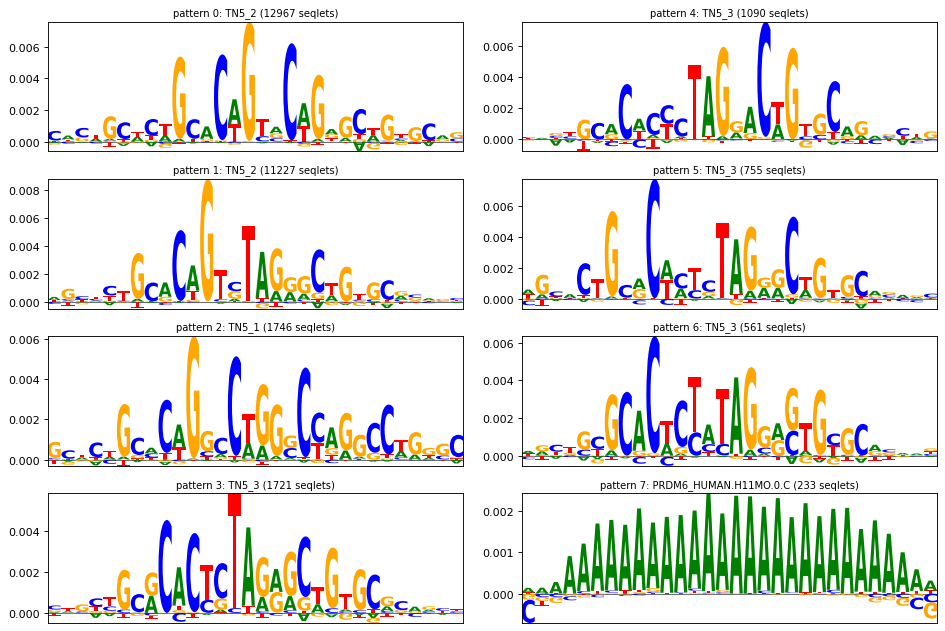

In [19]:
bias_modisco = h5py.File(f"{DATA}/modisco/bias_profile.h5", "r")
fig, axes = plt.subplots(4, 2, figsize=(12, 8))
for i, ax in enumerate(axes.T.flat):
    cwm = pd.DataFrame(bias_modisco["pos_patterns"][f"pattern_{i}"]["contrib_scores"][:], columns=list("ACGT"))
    logomaker.Logo(cwm, ax=ax)
    match = bias_motifs.set_index("pattern").loc[f"pos_patterns.pattern_{i}"]
    ax.set_title(f"pattern {i}: {match['match0']} ({match['num_seqlets']} seqlets)", fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

All large patterns match Tn5 motifs (`TN5_*`); the TF matches of small patterns have high q-values. Pattern 7 is a poly(A) tract. The bias model has not learned TF motifs.

## Step 5: training ChromBPNet

The main model has 8 dilated convolution layers with 512 filters, giving a receptive field that spans the input. It is trained on peaks and a subsample of background regions, with the frozen bias model added: the profile logits of both models are summed, as are their counts. The profile is trained with a multinomial negative log-likelihood, the counts with the mean squared error of log counts, weighted by `counts_loss_weight`. The resulting models are:

- `chrombpnet.h5`: bias model + main model; predicts the measured insertions.
- `chrombpnet_nobias.h5`: main model; used for interpretation.
- `bias_model_scaled.h5`: the bias model as used within `chrombpnet.h5`.

`scripts/chrombpnet/06_chrombpnet.sh` took 4.5 hours on an A100 GPU, of which 80 minutes training.

```bash
chrombpnet pipeline -ifrag microglia.fragments.tsv.gz -d ATAC -g mm10.fa -c mm10.main.chrom.sizes \
    -p peaks.narrowPeak -n nonpeaks_negatives.bed -fl fold_0.json -b bias/models/bias.h5 -o microglia
```

In [20]:
pd.read_csv(f"{DATA}/training/chrombpnet_model_params.tsv", sep="\t", header=None, names=["parameter", "value"])

,parameter,value
0,counts_loss_weight,20.5
1,filters,512
2,n_dil_layers,8
3,bias_model_path,/data/groups/vib.ai/stein.aerts/nkemp/software...
4,inputlen,2114
5,outputlen,1000
6,max_jitter,500
7,chr_fold_path,/data/groups/vib.ai/stein.aerts/nkemp/software...
8,negative_sampling_ratio,0.1


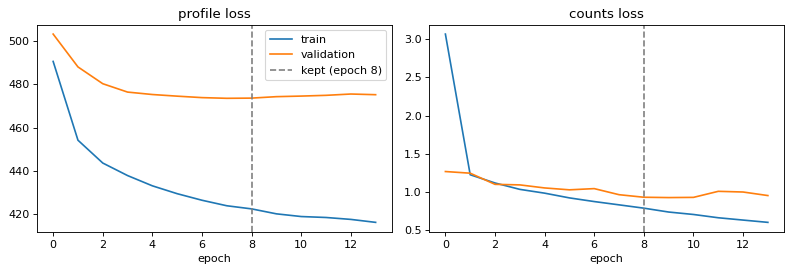

In [21]:
cbp_log = pd.read_csv(f"{DATA}/training/chrombpnet.log")
best = cbp_log.loc[cbp_log["val_loss"].idxmin(), "epoch"]   # lowest total validation loss
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, loss, title in zip(axes, ["logits_profile_predictions_loss", "logcount_predictions_loss"], ["profile", "counts"]):
    ax.plot(cbp_log["epoch"], cbp_log[loss], label="train")
    ax.plot(cbp_log["epoch"], cbp_log["val_" + loss], label="validation")
    ax.axvline(best, color="grey", ls="--", label=f"kept (epoch {best})")
    ax.set_xlabel("epoch")
    ax.set_title(f"{title} loss")
axes[0].legend()
plt.tight_layout()
plt.show()

The pipeline keeps the epoch with the lowest total validation loss, the profile loss plus `counts_loss_weight` times the counts loss (dashed line); training stopped 5 epochs later.

**At which epoch does overfitting start, and in which output?**

## Step 6: evaluation on the test chromosomes

Predicted counts on the test peaks (saved by the pipeline) against the measured insertions in the central 1,000 bp:

In [22]:
def load_predictions(path):
    with h5py.File(path, "r") as f:
        return pd.DataFrame({"chrom": f["coords/coords_chrom"][:].astype(str),
                             "summit": f["coords/coords_center"][:],
                             "pred_logcounts": f["predictions/logcounts"][:]})

test = load_predictions(f"{DATA}/evaluation/chrombpnet_predictions.h5")
test["bias_logcounts"] = load_predictions(f"{DATA}/evaluation/bias_predictions.h5")["pred_logcounts"]
# measured: insertions in the central 1,000 bp, on the same log scale as the model (log(1 + counts))
test["obs_logcounts"] = [np.log1p(np.nansum(insertions.values(c, int(s) - 500, int(s) + 500)))
                         for c, s in zip(test["chrom"], test["summit"])]
test.head()

,chrom,summit,pred_logcounts,bias_logcounts,obs_logcounts
0,chr18,3270727,4.982375,2.134611,3.784190
1,chr18,3280538,5.643917,1.728591,6.111467
2,chr18,3280821,6.668129,1.758132,6.695799
3,chr18,3281108,6.822835,1.852184,6.766192
4,chr18,3281432,6.036916,1.895200,6.481577


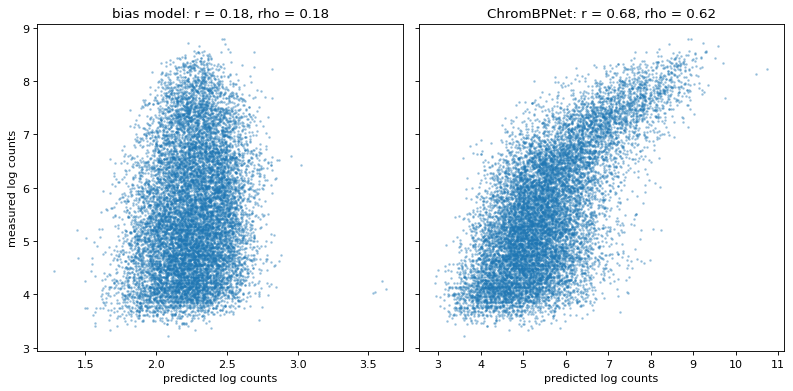

In [23]:
from scipy.stats import pearsonr, spearmanr

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, col, name in zip(axes, ["bias_logcounts", "pred_logcounts"], ["bias model", "ChromBPNet"]):
    ax.scatter(test[col], test["obs_logcounts"], s=2, alpha=0.3)
    r = pearsonr(test[col], test["obs_logcounts"])[0]
    rho = spearmanr(test[col], test["obs_logcounts"])[0]
    ax.set_title(f"{name}: r = {r:.2f}, rho = {rho:.2f}")
    ax.set_xlabel("predicted log counts")
axes[0].set_ylabel("measured log counts")
plt.tight_layout()
plt.show()

The bias model does not predict peak strength; ChromBPNet does (the ChromBPNet authors consider r > 0.5 on test peaks acceptable).

Predicted profiles of the three models at FIRE, a strong test peak (rank 100) and a median test peak:

In [24]:
import tensorflow as tf
from tensorflow.keras.utils import get_custom_objects
from chrombpnet.training.utils.losses import multinomial_nll
from chrombpnet.training.utils.one_hot import dna_to_one_hot
from scipy.special import softmax

get_custom_objects().update({"multinomial_nll": multinomial_nll, "tf": tf})
models = {name: tf.keras.models.load_model(f"{DATA}/models/{name}.h5", compile=False)
          for name in ["chrombpnet", "chrombpnet_nobias", "bias_model_scaled"]}

2026-11-13 11:41:27.446662: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /mnt/modules/easybuild/software/util-linux/2.40-GCCcore-13.3.0/lib:/mnt/modules/easybuild/software/SQLite/3.45.3-GCCcore-13.3.0/lib:/mnt/modules/easybuild/software/Tcl/8.6.14-GCCcore-13.3.0/lib:/mnt/modules/easybuild/software/libreadline/8.2-GCCcore-13.3.0/lib:/mnt/modules/easybuild/software/zlib/1.3.1-GCCcore-13.3.0/lib:/mnt/modules/easybuild/software/ncurses/6.5-GCCcore-13.3.0/lib:/mnt/modules/easybuild/software/GCCcore/13.3.0/lib64:/mnt/modules/easybuild/software/SciPy-bundle/2023.02-gfbf-2022b/lib/python3.10/site-packages/numpy/core/lib:/mnt/modules/easybuild/software/ScaLAPACK/2.2.0-gompi-2022b-fb/lib:/mnt/modules/easybuild/software/FFTW.MPI/3.3.10-gompi-2022b/lib:/mnt/modules/easybuild/software/FFTW/3.3.10-GCC-12.2.0/lib:/mnt/modules/ea

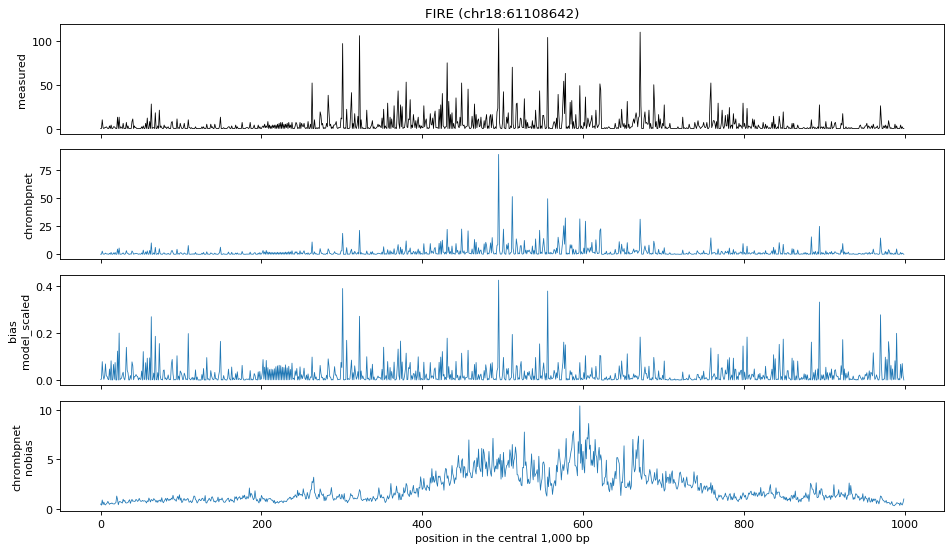

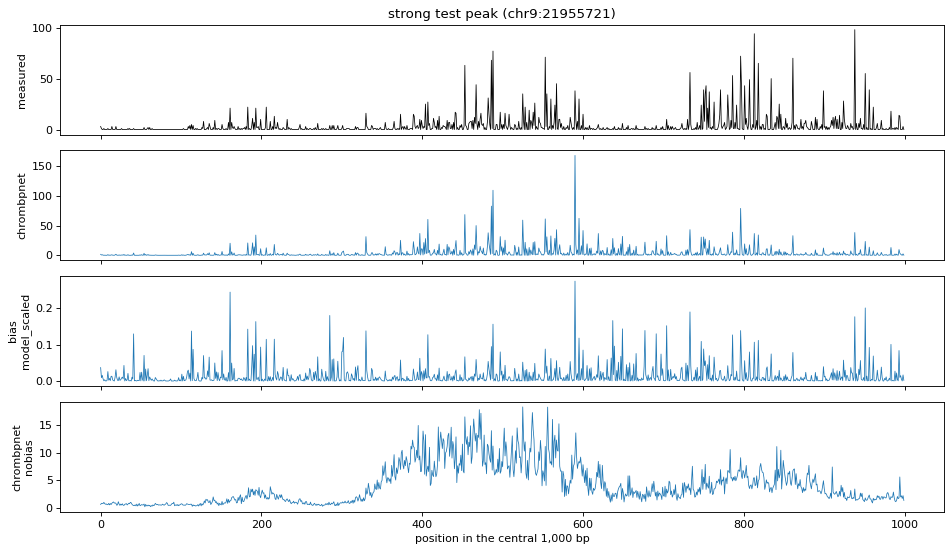

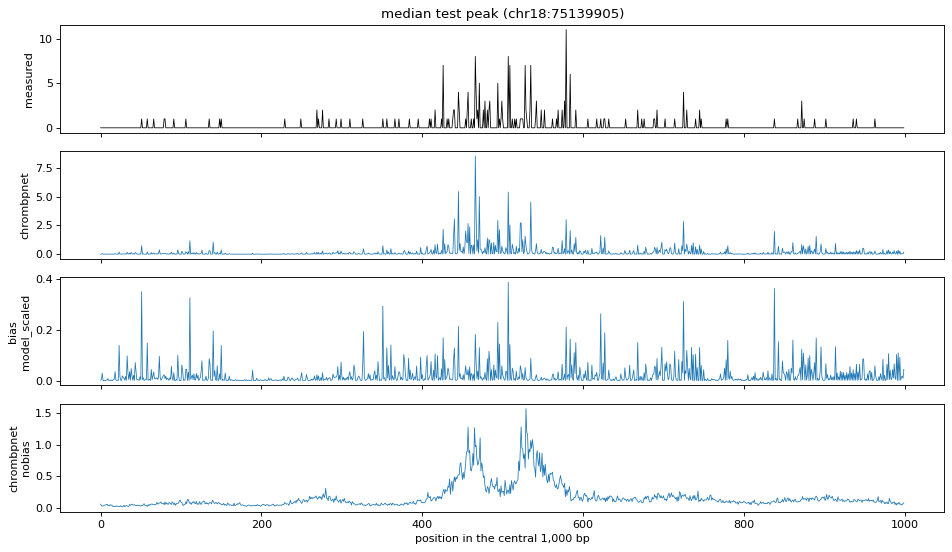

In [25]:
test = test.sort_values("obs_logcounts", ascending=False).reset_index(drop=True)
examples = {"FIRE": ("chr18", int(FIRE_SUMMIT)),
            "strong test peak": (test.loc[100, "chrom"], int(test.loc[100, "summit"])),
            "median test peak": (test.loc[len(test) // 2, "chrom"], int(test.loc[len(test) // 2, "summit"]))}

for name, (chrom, summit) in examples.items():
    x = dna_to_one_hot([str(genome[chrom][summit - 1057:summit + 1057])])
    obs = np.nan_to_num(insertions.values(chrom, summit - 500, summit + 500, numpy=True))
    fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(obs, color="black", lw=0.7)
    axes[0].set_ylabel("measured")
    axes[0].set_title(f"{name} ({chrom}:{summit})")
    for ax, model in zip(axes[1:], ["chrombpnet", "bias_model_scaled", "chrombpnet_nobias"]):
        logits, logcounts = models[model].predict(x, verbose=0)
        ax.plot(softmax(logits[0]) * np.exp(logcounts[0, 0]), lw=0.7)
        ax.set_ylabel(model.replace("_", "\n", 1))
    axes[-1].set_xlabel("position in the central 1,000 bp")
    plt.tight_layout()
    plt.show()

The full model reproduces the measured profile, including many sharp peaks. The bias model predicts spikes at the same positions with low total counts, so these spikes reflect Tn5 preference. The bias-corrected model predicts a smooth profile. At FIRE, the predicted counts (about 2,000) are lower than measured (about 5,100); the strongest peaks are generally underpredicted (scatter plot above).

**Which spikes in the measured profile are explained by the bias model?**

## Step 7: contribution scores at FIRE

Contribution scores of the bias-corrected model are computed with DeepSHAP, relative to dinucleotide-shuffled versions of the input, for the counts and the profile output. `chrombpnet contribs_bw` takes regions in narrowPeak format and writes HDF5 and bigWig files (about 1 minute per region on a CPU).

Hecker et al. (2025) compared the contribution scores of FIRE across sequence-to-function models (CREsted models of mouse, human and chicken brain, a microglia ChromBPNet model and Enformer) with in-silico mutagenesis and with mutations tested by MPRA, and annotated eight sites: Spi1, Sp1/3, Ets–Runx, AP-1, Spi1, Mafb–Runx, Cebp and Stat. We plot the same region, with these sites shaded.

In [26]:
peaks[peaks["name"] == "microglia_peak_57271c"].to_csv(RESULTS / "fire.bed", sep="\t", header=False, index=False)
!chrombpnet contribs_bw -m {DATA}/models/chrombpnet_nobias.h5 -r {RESULTS}/fire.bed -g {FASTA} -c {CHROM_SIZES} -op {RESULTS}/fire -pc counts profile 2> {RESULTS}/fire_contribs.log
!ls {RESULTS}

got the model
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 sequence (InputLayer)          [(None, 2114, 4)]    0           []                               
                                                                                                  
 wo_bias_bpnet_1st_conv (Conv1D  (None, 2094, 512)   43520       ['sequence[0][0]']               
 )                                                                                                
                                                                                                  
 wo_bias_bpnet_1conv (Conv1D)   (None, 2090, 512)    786944      ['wo_bias_bpnet_1st_conv[0][0]'] 
                                                                                                  
 wo_bias_bpnet_1crop (Cropping1  (None, 2090, 512)   0           ['wo_bias_bpn

Saving 'profile' scores


fire.bed	       fire.counts_scores.h5	     fire.profile_scores.bw
fire_contribs.log      fire.interpret.args.json      fire.profile_scores.h5
fire.counts_scores.bw  fire.interpreted_regions.bed


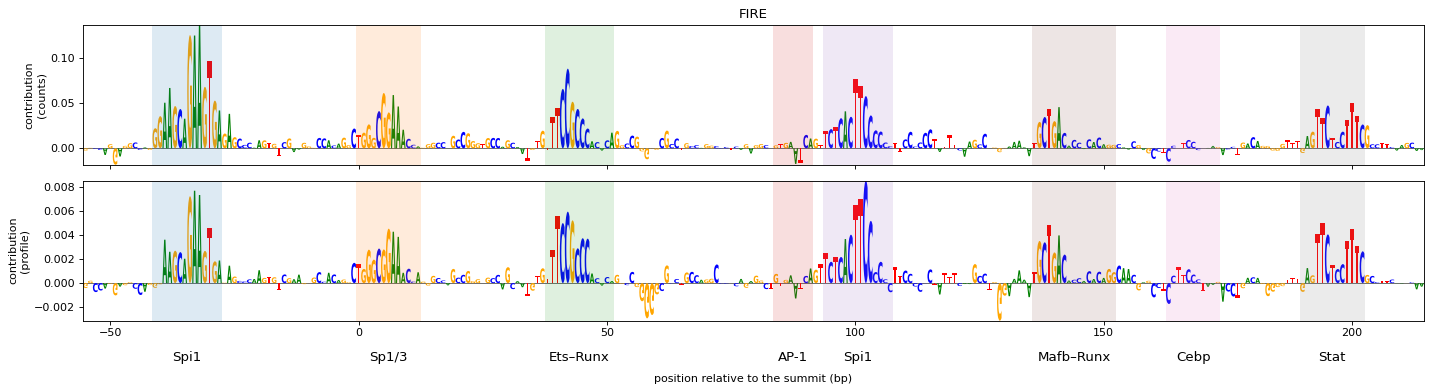

In [27]:
contribs = {}
for head in ["counts", "profile"]:
    scores = dd.io.load(f"{RESULTS}/fire.{head}_scores.h5")
    # projected_shap: the score of the base that is present at each position, shape (regions, 4, 2114)
    contribs[head] = pd.DataFrame(scores["projected_shap"]["seq"][0].T.astype(float), columns=list("ACGT"))

# region and sites of FIRE as annotated by Hecker et al. (2025), in bp relative to the summit
WINDOW = (-55, 215)
SITES = [("Spi1", -41, -28), ("Sp1/3", 0, 12), ("Ets–Runx", 38, 51), ("AP-1", 84, 91), ("Spi1", 94, 107),
         ("Mafb–Runx", 136, 152), ("Cebp", 163, 173), ("Stat", 190, 202)]
positions = np.arange(WINDOW[0], WINDOW[1])

fig, axes = plt.subplots(2, 1, figsize=(18, 5), sharex=True)
for ax, head in zip(axes, ["counts", "profile"]):
    window = contribs[head].iloc[1057 + WINDOW[0]:1057 + WINDOW[1]].set_axis(positions)
    logomaker.Logo(window, ax=ax)
    ax.set_ylabel(f"contribution\n({head})")
    for i, (name, start, end) in enumerate(SITES):
        ax.axvspan(start - 0.5, end + 0.5, color=f"C{i}", alpha=0.15, lw=0)
for name, start, end in SITES:
    axes[-1].text((start + end) / 2, -0.22, name, transform=axes[-1].get_xaxis_transform(), ha="center", va="top", fontsize=12)
axes[0].set_title("FIRE")
axes[-1].set_xlabel("position relative to the summit (bp)", labelpad=32)
plt.tight_layout()
plt.show()

The largest contributions are at the two Spi1 (PU.1) sites, followed by the Ets–Runx, Sp1/3, Mafb–Runx and Stat sites; the AP-1 and Cebp sites contribute little. Both outputs use largely the same sites.

**Compare with the CREsted `Micro_PVM` contribution scores of FIRE in part 1 (the CREsted window is centred about 185 bp further right) and with the models in Hecker et al. (2025). Which sites do all models use?**

## Step 8: TF-MoDISco

TF-MoDISco extracts high-contribution subsequences (seqlets) from the contribution scores of 30,000 peaks and clusters them into motifs. The pipeline ran it on the profile scores, `scripts/chrombpnet/07_interpret.sh` and `scripts/chrombpnet/08_modisco.sh` on the counts scores. Profile motifs, sorted by number of seqlets, with their TOMTOM matches (made as in Step 4):

In [28]:
profile_motifs = pd.read_csv(f"{DATA}/modisco/chrombpnet_profile_tomtom.tsv", sep="\t")
profile_motifs[profile_motifs["pattern"].str.startswith("pos")].head(20)

,pattern,num_seqlets,match0,qval0,match1,qval1,match2,qval2
0,pos_patterns.pattern_0,11153,SPI1_MOUSE.H11MO.0.A,7.286650e-07,SPI1_HUMAN.H11MO.0.A,7.286650e-07,SPIB_HUMAN.H11MO.0.A,1.259970e-06
1,pos_patterns.pattern_1,3617,CTCF_MA0139.1,7.062930e-13,CTCF_HUMAN.H11MO.0.A,5.385500e-10,CTCF_MOUSE.H11MO.0.A,2.918430e-09
2,pos_patterns.pattern_2,1952,KLF12_HUMAN.H11MO.0.C,1.962590e-04,SP1_HUMAN.H11MO.0.A,2.206840e-04,SP3_HUMAN.H11MO.0.B,2.206840e-04
3,pos_patterns.pattern_3,1138,NFYC_HUMAN.H11MO.0.A,7.118480e-04,NFYB_HUMAN.H11MO.0.A,7.118480e-04,NFYB_MOUSE.H11MO.0.A,7.118480e-04
4,pos_patterns.pattern_4,831,IRF4_HUMAN.H11MO.0.A,3.420320e-06,IRF8_HUMAN.H11MO.0.B,3.420320e-06,IRF8_MOUSE.H11MO.0.A,3.420320e-06
5,pos_patterns.pattern_5,742,MAF_HUMAN.H11MO.0.A,1.228440e-08,MAF_MOUSE.H11MO.0.A,4.328340e-08,MAFB_HUMAN.H11MO.0.B,5.535840e-08
6,pos_patterns.pattern_6,623,MEF2D_HUMAN.H11MO.0.A,2.966990e-10,MEF2D_MOUSE.H11MO.0.A,2.966990e-10,MEF2C_HUMAN.H11MO.0.A,3.235590e-07
7,pos_patterns.pattern_7,617,FOSB+JUN_MA1127.1,7.010480e-05,FOSL2+JUN_MA1131.1,7.010480e-05,CREB1_HUMAN.H11MO.0.A,9.625970e-05
8,pos_patterns.pattern_8,616,NRF1_HUMAN.H11MO.0.A,4.158280e-06,NRF1_MOUSE.H11MO.0.A,4.158280e-06,NRF1_NRF_1,1.168120e-05
9,pos_patterns.pattern_9,592,NFIC_HUMAN.H11MO.0.A,1.764170e-05,NFIA_HUMAN.H11MO.0.C,1.764170e-05,NFIA_MOUSE.H11MO.0.C,1.764170e-05


Contribution weight matrices (CWMs: mean contribution per base over all seqlets) of the 12 largest patterns, with the best TOMTOM match:

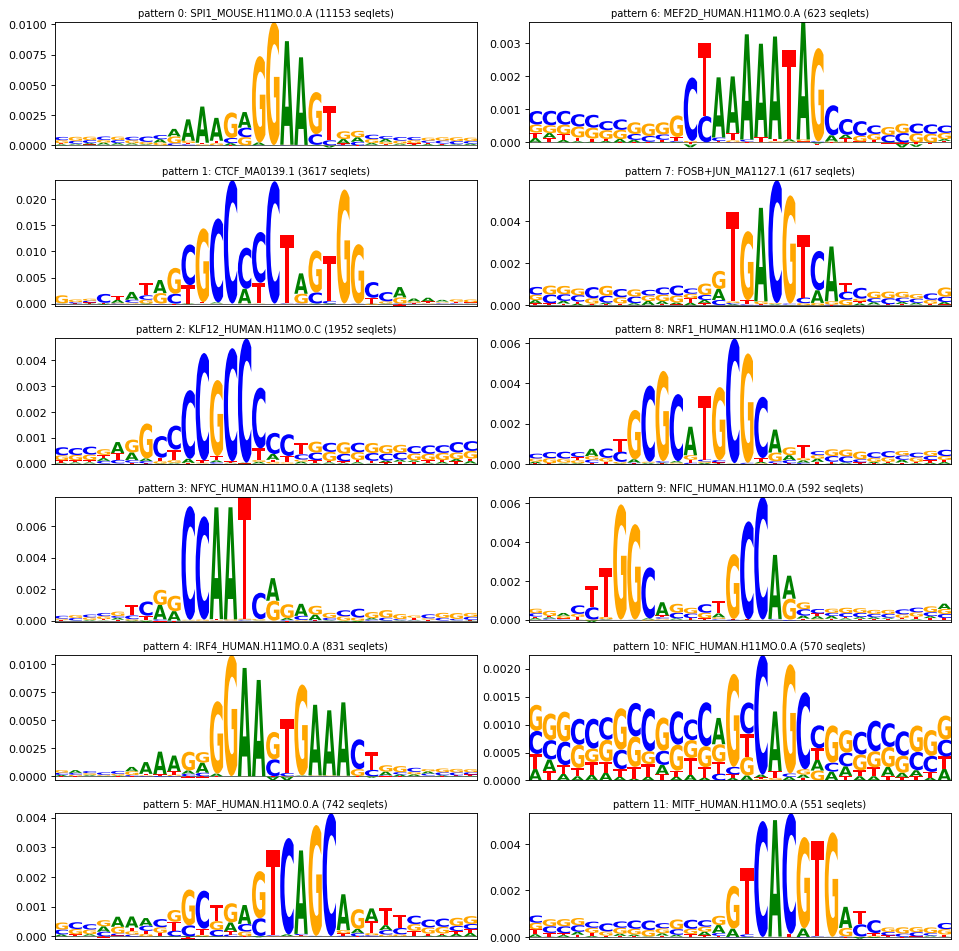

In [29]:
modisco = h5py.File(f"{DATA}/modisco/chrombpnet_profile.h5", "r")
fig, axes = plt.subplots(6, 2, figsize=(12, 12))
for i, ax in enumerate(axes.T.flat):
    pattern = modisco["pos_patterns"][f"pattern_{i}"]
    cwm = pd.DataFrame(pattern["contrib_scores"][:], columns=list("ACGT"))
    logomaker.Logo(cwm, ax=ax)
    match = profile_motifs.set_index("pattern").loc[f"pos_patterns.pattern_{i}"]
    ax.set_title(f"pattern {i}: {match['match0']} ({match['num_seqlets']} seqlets)", fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

PU.1 is the most frequent motif, followed by motifs of other microglia TFs (PU.1–IRF composite element, MAF, MEF2, CEBP, MITF/TFE) and of TFs active in most cell types (CTCF, SP/KLF, NFY, NRF1). No Tn5 motifs remain.

**Which of these motifs would you expect to be absent in neurons? Compare with the enhancer code notebooks.**

Counts motifs:

In [30]:
counts_motifs = pd.read_csv(f"{DATA}/modisco/chrombpnet_counts_tomtom.tsv", sep="\t")
counts_motifs[counts_motifs["pattern"].str.startswith("pos")].head(20)

,pattern,num_seqlets,match0,qval0,match1,qval1,match2,qval2
0,pos_patterns.pattern_0,13729,ELK1_ETS_1,1.298450e-02,ELK1_ETS_2,1.298450e-02,ELK1_ETS_4,1.298450e-02
1,pos_patterns.pattern_1,4171,CTCF_MA0139.1,1.715790e-16,CTCF_HUMAN.H11MO.0.A,6.811610e-12,CTCF_MOUSE.H11MO.0.A,2.206570e-10
2,pos_patterns.pattern_2,1760,KLF12_HUMAN.H11MO.0.C,2.685500e-04,SP1_HUMAN.H11MO.0.A,2.685500e-04,SP4_HUMAN.H11MO.0.A,6.188780e-04
3,pos_patterns.pattern_3,1128,IRF4_HUMAN.H11MO.0.A,1.061560e-06,IRF8_HUMAN.H11MO.0.B,1.061560e-06,IRF8_MOUSE.H11MO.0.A,1.061560e-06
4,pos_patterns.pattern_4,1077,NFYB_HUMAN.H11MO.0.A,1.414640e-03,NFYB_MOUSE.H11MO.0.A,1.414640e-03,NFYA_HUMAN.H11MO.0.A,1.482010e-03
5,pos_patterns.pattern_5,875,MEF2A_MOUSE.H11MO.0.A,5.999850e-07,MEF2D_HUMAN.H11MO.0.A,1.531250e-06,MEF2D_MOUSE.H11MO.0.A,1.531250e-06
6,pos_patterns.pattern_6,816,NRF1_MA0506.1,3.096110e-06,NRF1_MOUSE.H11MO.0.A,4.737960e-05,NRF1_HUMAN.H11MO.0.A,4.737960e-05
7,pos_patterns.pattern_7,641,MAF_HUMAN.H11MO.0.A,7.627580e-09,MAF_MOUSE.H11MO.0.A,2.643920e-08,MAFG_HUMAN.H11MO.0.A,3.944180e-08
8,pos_patterns.pattern_8,495,CEBPB_MA0466.2,1.169250e-04,CEBPB_bZIP_1,1.169250e-04,CEBPE_MA0837.1,1.169250e-04
9,pos_patterns.pattern_9,479,NFIC_HUMAN.H11MO.0.A,5.551410e-05,NFIA_HUMAN.H11MO.0.C,7.656260e-05,NFIA_MOUSE.H11MO.0.C,7.656260e-05


The two motif sets are largely the same; TOMTOM assigns some patterns to other members of the same family (pattern 0 to ELK1, the CRE to ATF1/CREB1).

## Step 9: marginal footprints

A marginal footprint is the mean predicted profile after inserting a motif in the centre of many background sequences; sequence effects other than the motif average out. `scripts/chrombpnet/07_interpret.sh` ran `chrombpnet footprints` with the consensus sequences of the main TF-MoDISco motifs on the background regions of the test chromosomes, for the full and the bias-corrected model.

```bash
chrombpnet footprints -m microglia/models/chrombpnet_nobias.h5 -r nonpeaks_negatives.bed -g mm10.fa -fl fold_0.json \
    -op footprints/chrombpnet_nobias -pwm_f footprints/motifs.tsv
```

In [31]:
footprint_motifs = pd.read_csv(f"{DATA}/footprints/motifs.tsv", sep="\t", header=None, names=["motif", "sequence"])
footprints = {model: dd.io.load(f"{DATA}/footprints/{model}_footprints.h5") for model in ["chrombpnet_nobias", "chrombpnet"]}
footprint_motifs

,motif,sequence
0,PU.1,AAGAGGAAGT
1,PU.1-IRF,GGAAGTGAAAC
2,IRF,GAAACTGAAACT
3,CEBP,GTTGCACAAT
4,MEF2,CTAAAAATAGC
5,MAF,GCTGAGTCAGCA
6,MITF-TFE,GTCACGTG
7,CTCF,CGCCCCCTGGTGG
8,SP-KLF,GCCCCGCCC
9,NFY,CCAATCA


`footprints[model][motif]` holds the mean predicted profile (1,000 bp) and the mean predicted counts. Central 200 bp, with the background sequences without insertion as `control`:

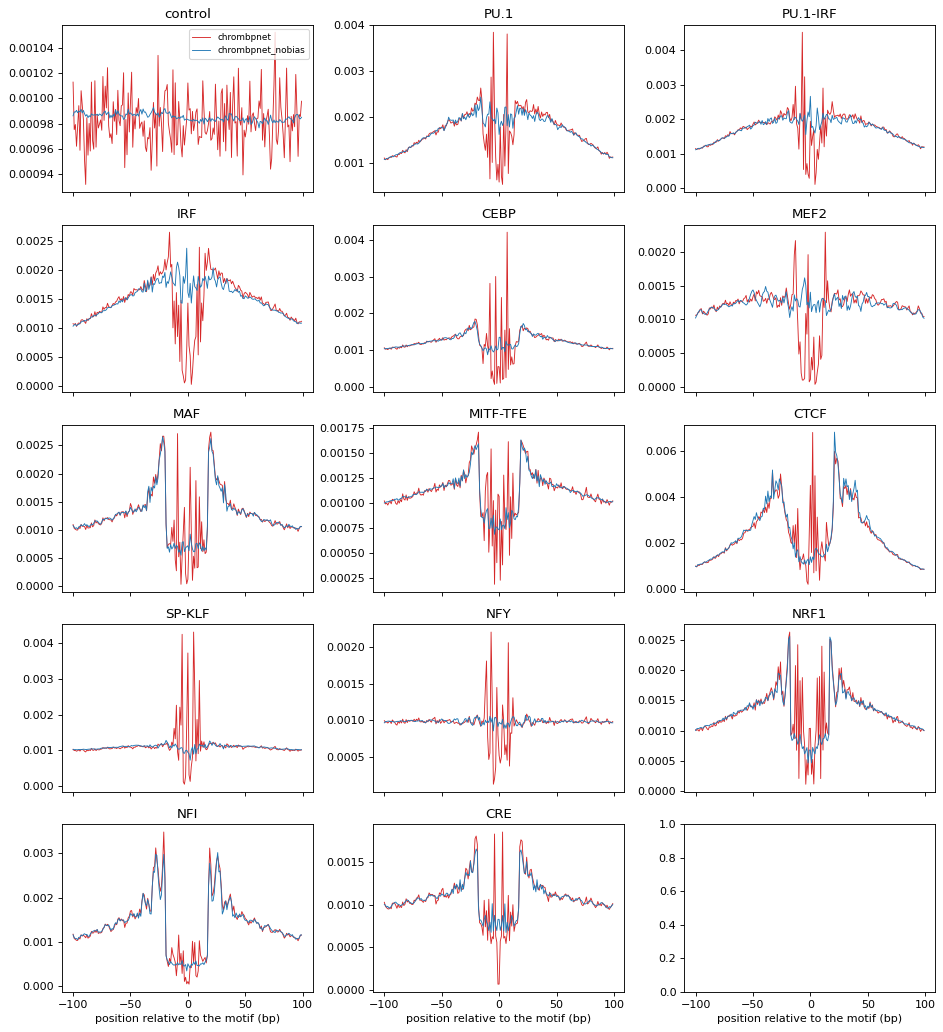

In [32]:
fig, axes = plt.subplots(5, 3, figsize=(12, 13), sharex=True)
for ax, motif in zip(axes.flat, ["control"] + list(footprint_motifs["motif"])):
    for model, color in [("chrombpnet", "tab:red"), ("chrombpnet_nobias", "tab:blue")]:
        ax.plot(np.arange(-100, 100), footprints[model][motif][0][400:600], color=color, lw=0.8, label=model)
    ax.set_title(motif)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("position relative to the motif (bp)")
plt.tight_layout()
plt.show()

The control profiles are flat for both models (note the y-axis), as Tn5 preference averages out over different sequences. With an inserted motif, the full model shows sharp spikes and dips within the motif, caused by Tn5 preference for the fixed motif sequence. The bias-corrected model shows increased insertions over about 100 bp around the motif and, for some TFs, a depletion at the motif itself (protection from Tn5). Without bias correction, Tn5 dips could be mistaken for TF footprints.

**Which motifs show a footprint? Is footprint depth related to the effect on accessibility?** Effect of each motif on the predicted counts:

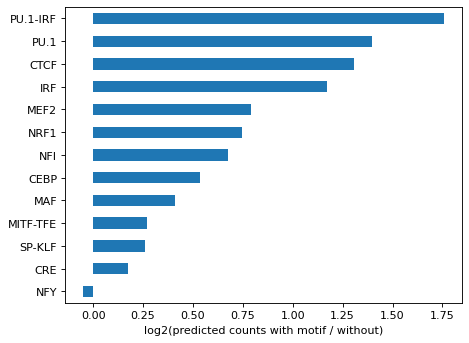

In [33]:
counts_gain = {motif: np.log2(footprints["chrombpnet_nobias"][motif][1][0] / footprints["chrombpnet_nobias"]["control"][1][0])
               for motif in footprint_motifs["motif"]}
pd.Series(counts_gain).sort_values().plot.barh()
plt.xlabel("log2(predicted counts with motif / without)")
plt.show()

## Step 10: in-silico mutagenesis of FIRE

Effect of sequence changes on the predicted counts of the bias-corrected model. First, the first Spi1 site (15 bp starting 42 bp left of the summit) is replaced by random sequence:

GGCCAGGGAAGCAGAAGTGA
GGCCATGGCCAAAATGTGGT


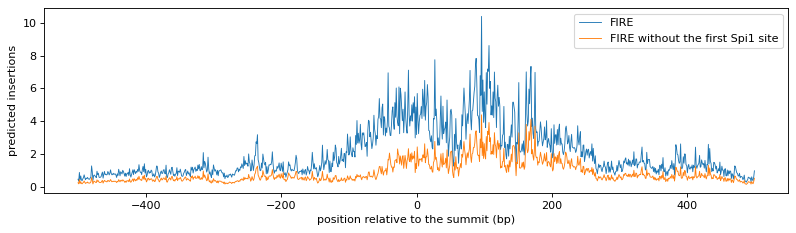

predicted counts: 2044 -> 888


In [34]:
fire_seq = str(genome["chr18"][FIRE_SUMMIT - 1057:FIRE_SUMMIT + 1057]).upper()
rng = np.random.default_rng(0)
start = 1057 - 42
mutant = fire_seq[:start] + "".join(rng.choice(list("ACGT"), 15)) + fire_seq[start + 15:]
print(fire_seq[start - 5:start + 15])
print(mutant[start - 5:start + 15])

logits, logcounts = models["chrombpnet_nobias"].predict(dna_to_one_hot([fire_seq, mutant]), verbose=0)
plt.figure(figsize=(12, 3))
for i, name in enumerate(["FIRE", "FIRE without the first Spi1 site"]):
    plt.plot(np.arange(-500, 500), softmax(logits[i]) * np.exp(logcounts[i, 0]), lw=0.8, label=name)
plt.xlabel("position relative to the summit (bp)")
plt.ylabel("predicted insertions")
plt.legend()
plt.show()
print("predicted counts: %.0f -> %.0f" % tuple(np.exp(logcounts[:, 0])))

Saturation mutagenesis over the region of Step 7: each base is substituted by each of the three alternative bases (810 sequences, about 1 minute on a CPU), and the change in predicted log2 counts is plotted per substitution, as in Hecker et al. (2025).

In [35]:
variants, index = [], []
for p in positions:
    for base in "ACGT":
        if base != fire_seq[1057 + p]:
            variants.append(fire_seq[:1057 + p] + base + fire_seq[1057 + p + 1:])
            index.append((p, base))

ref_logcounts = models["chrombpnet_nobias"].predict(dna_to_one_hot([fire_seq]), verbose=0)[1][0, 0]
var_logcounts = models["chrombpnet_nobias"].predict(dna_to_one_hot(variants), batch_size=64, verbose=0)[1][:, 0]
ism = pd.DataFrame(index, columns=["position", "base"])
ism["delta_log2_counts"] = (var_logcounts - ref_logcounts) / np.log(2)
ism.sort_values("delta_log2_counts").head()

,position,base,delta_log2_counts
70,-32,G,-1.386124
47,-40,T,-1.194061
67,-33,G,-1.092243
66,-33,C,-1.058367
65,-34,T,-1.050680


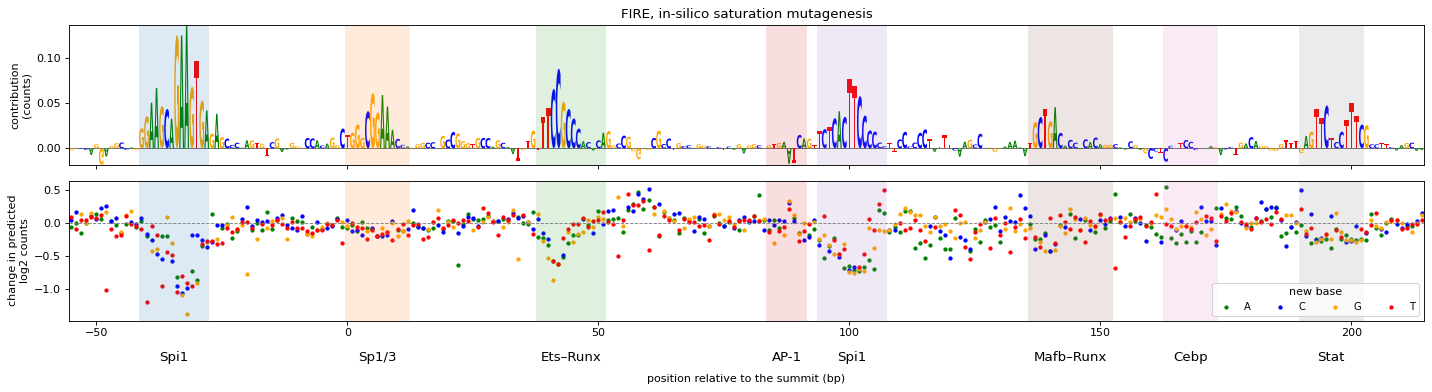

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(18, 5), sharex=True)
window = contribs["counts"].iloc[1057 + WINDOW[0]:1057 + WINDOW[1]].set_axis(positions)
logomaker.Logo(window, ax=axes[0])
axes[0].set_ylabel("contribution\n(counts)")
for base, color in zip("ACGT", ["green", "blue", "orange", "red"]):
    sub = ism[ism["base"] == base]
    axes[1].scatter(sub["position"], sub["delta_log2_counts"], s=8, color=color, label=base)
axes[1].axhline(0, color="grey", ls="--", lw=0.8)
axes[1].set_ylabel("change in predicted\nlog2 counts")
axes[1].legend(title="new base", loc="lower right", ncol=4, fontsize=9)
for ax in axes:
    for i, (name, start, end) in enumerate(SITES):
        ax.axvspan(start - 0.5, end + 0.5, color=f"C{i}", alpha=0.15, lw=0)
for name, start, end in SITES:
    axes[-1].text((start + end) / 2, -0.22, name, transform=axes[-1].get_xaxis_transform(), ha="center", va="top", fontsize=12)
axes[0].set_title("FIRE, in-silico saturation mutagenesis")
axes[-1].set_xlabel("position relative to the summit (bp)", labelpad=32)
plt.tight_layout()
plt.show()

Substitutions in the first Spi1 site, the Ets–Runx site and the second Spi1 site reduce the predicted counts most; substitutions in the Mafb, Stat and Sp1/3 sites have smaller effects, and the AP-1 and Cebp sites are hardly affected. Outside the sites, some substitutions increase the counts, for example by creating a better motif match. Compare with the in-silico and MPRA mutagenesis of FIRE in Hecker et al. (2025).

**Which single substitution has the largest effect, and how does it compare with removing the whole first Spi1 site?**

## Conclusion

1. ChromBPNet predicts Tn5 insertion counts in microglia on held-out chromosomes (r = 0.68) and the shape of the profile; the strongest peaks are underpredicted.
2. A large part of the base-level profile reflects the sequence preference of Tn5, which the bias model captures without learning TF motifs.
3. The bias-corrected model uses motifs of the microglia program (PU.1, PU.1–IRF, MAF, MEF2, CEBP, MITF/TFE) and of TFs active in most cell types (CTCF, SP/KLF, NFY, NRF1).
4. Footprint depth and effect on accessibility are not coupled: PU.1 has one of the largest effects on predicted counts but a shallow footprint.
5. The predicted accessibility of FIRE depends mostly on its two Spi1 sites and the Ets–Runx site, consistent with the models and mutagenesis in Hecker et al. (2025).

ChromBPNet models a single cell type at base resolution, which allows bias correction and footprint analysis. The drawback is that every cell type needs its own model, trained on deep enough data: the 19 cortex cell types of part 1 would require 19 ChromBPNet models (each about 1.5 hours of GPU training here, plus interpretation), whereas one CREsted model covers all of them and allows direct comparison between cell types.

## Exercises

1. Repeat Steps 7 and 10 for the strong test peak of Step 6. Which motifs does it contain?
2. Mutate the other high-contribution sites of FIRE one at a time and together. Are the effects additive?
3. Insert the consensus sequence of a motif from `footprint_motifs` into the median test peak of Step 6 and predict the counts.
4. Select test peaks that ChromBPNet underpredicts most (Step 6) and inspect their contribution scores. What might the model be missing?
5. Why could a motif affect the counts but not the profile of a region (Step 8)?

### References

1. Pampari A, Shcherbina A, Kvon EZ, et al. (2024). ChromBPNet: bias factorized, base-resolution deep learning models of chromatin accessibility reveal cis-regulatory sequence syntax, transcription factor footprints and regulatory variants. *bioRxiv*. Code and documentation: https://github.com/kundajelab/chrombpnet
2. Avsec Ž, Weilert M, Shrikumar A, et al. (2021). Base-resolution models of transcription-factor binding reveal soft motif syntax. *Nature Genetics* 53, 354–366.
3. Zemke NR, Armand EJ, Wang W, et al. (2023). Conserved and divergent gene regulatory programs of the mammalian neocortex. *Nature* 624, 390–402.
4. Shrikumar A, Tian K, Avsec Ž, et al. (2018). Technical note on Transcription Factor Motif Discovery from Importance Scores (TF-MoDISco). *arXiv* 1811.00416.
5. Zhang H, Song L, Wang X, et al. (2021). Fast alignment and preprocessing of chromatin profiles with Chromap. *Nature Communications* 12, 6566.
6. Kierdorf K, Erny D, Goldmann T, et al. (2013). Microglia emerge from erythromyeloid precursors via Pu.1- and Irf8-dependent pathways. *Nature Neuroscience* 16, 273–280.
7. Gosselin D, Link VM, Romanoski CE, et al. (2014). Environment drives selection and function of enhancers controlling tissue-specific macrophage identities. *Cell* 159, 1327–1340.
8. Rojo R, Raper A, Ozdemir DD, et al. (2019). Deletion of a Csf1r enhancer selectively impacts CSF1R expression and development of tissue macrophage populations. *Nature Communications* 10, 3215.
9. Hecker N, Kempynck N, Mauduit D, et al. (2025). Enhancer-driven cell type comparison reveals similarities between the mammalian and bird pallium. *Science* 387, eadp3957.